# Notebook 1. Análisis exploratorio de datos (EDA) y preprocesamiento

**Proyecto:** MamaIA – clasificación de tumores mamarios benignos y malignos.

## Objetivo
Explorar el conjunto Breast Cancer Wisconsin (Diagnostic), revisar su calidad, estudiar la distribución de la variable objetivo y preparar las diez variables medias que utiliza la aplicación desplegada.

**Criterio del proyecto:** `maligno = 1` y `benigno = 0`. La clase positiva es maligno; por ello, en la evaluación posterior se prestará especial atención al *recall* (sensibilidad).

> Ejecuta las celdas en orden. El notebook intenta leer `datos.csv` desde la carpeta actual o desde la carpeta superior. Si no encuentra un CSV compatible, utiliza el conjunto Wisconsin integrado en scikit-learn, con las mismas diez variables.

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn

In [2]:

from pathlib import Path
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

SEED = 42
FEATURES = [
    "mean radius", "mean texture", "mean perimeter", "mean area",
    "mean smoothness", "mean compactness", "mean concavity",
    "mean concave points", "mean symmetry", "mean fractal dimension"
]

def normalizar(texto):
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z0-9]+", "", texto.lower())

def cargar_dataset():
    """Busca el CSV del repositorio; si no está, usa el mismo dataset Wisconsin de scikit-learn."""
    candidatos = [Path("datos.csv"), Path("../datos.csv"), Path("data/datos.csv")]
    archivo = next((p for p in candidatos if p.exists()), None)

    if archivo:
        bruto = pd.read_csv(archivo)
        # Mapear nombres alternativos a los diez nombres canónicos.
        aliases = {
            "meanradius": "mean radius", "radiome dio": "mean radius",
            "meantexture": "mean texture", "texturamedia": "mean texture",
            "meanperimeter": "mean perimeter", "perimetromedio": "mean perimeter",
            "meanarea": "mean area", "areamedia": "mean area",
            "meansmoothness": "mean smoothness", "suavidadmedia": "mean smoothness",
            "meancompactness": "mean compactness", "compactacionmedia": "mean compactness",
            "meanconcavity": "mean concavity", "concavidadmedia": "mean concavity",
            "meanconcavepoints": "mean concave points", "puntosconcavosmedios": "mean concave points",
            "meansymmetry": "mean symmetry", "simetriamedia": "mean symmetry",
            "meanfractaldimension": "mean fractal dimension", "dimensionfractralmedia": "mean fractal dimension",
            "maligno": "maligno", "diagnostico": "maligno", "diagnosis": "maligno",
            "target": "maligno", "label": "maligno", "class": "maligno"
        }
        renombrar = {}
        for c in bruto.columns:
            k = normalizar(c)
            if k in aliases:
                renombrar[c] = aliases[k]
            elif k == "meanconcavepoints":
                renombrar[c] = "mean concave points"
            elif k == "meanfractaldimension":
                renombrar[c] = "mean fractal dimension"
        df = bruto.rename(columns=renombrar)
        if all(c in df.columns for c in FEATURES) and "maligno" in df.columns:
            X = df[FEATURES].apply(pd.to_numeric, errors="coerce")
            raw_y = df["maligno"]
            if pd.api.types.is_numeric_dtype(raw_y):
                y = pd.to_numeric(raw_y, errors="coerce")
                # En este proyecto, 1 = maligno y 0 = benigno.
                if set(y.dropna().unique()).issubset({0, 1}):
                    y = y.astype(int)
                else:
                    raise ValueError("La etiqueta numérica debe estar codificada como 0=benigno y 1=maligno.")
            else:
                etiquetas = raw_y.astype(str).str.strip().str.lower()
                mapa = {"m": 1, "maligno": 1, "malignant": 1, "b": 0, "benigno": 0, "benign": 0}
                y = etiquetas.map(mapa)
            datos = X.copy()
            datos["maligno"] = y
            datos = datos.dropna()
            return datos[FEATURES], datos["maligno"].astype(int), f"CSV: {archivo}"
        print(f"El archivo {archivo} no contiene las 10 variables y la etiqueta esperadas; se usará el dataset integrado.")

    cancer = load_breast_cancer(as_frame=True)
    X = cancer.data[FEATURES].copy()
    # En scikit-learn: target=0 es maligno y target=1 es benigno.
    y = (cancer.target == 0).astype(int).rename("maligno")
    return X, y, "Breast Cancer Wisconsin Diagnostic (scikit-learn)"

X, y, fuente_datos = cargar_dataset()
df = X.copy()
df["maligno"] = y
print("Fuente:", fuente_datos)
print("Dimensiones:", df.shape)
print("Codificación: 0 = benigno | 1 = maligno")


Fuente: CSV: datos.csv
Dimensiones: (569, 11)
Codificación: 0 = benigno | 1 = maligno


## 1. Vista inicial y estructura de los datos
Se revisan las primeras observaciones, los tipos de datos y las dimensiones.

In [3]:
display(df.head())
print('\nInformación general:')
df.info()
print('\nEstadísticos descriptivos:')
display(df.describe().T)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,maligno
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,1



Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   mean radius             569 non-null    float64
 1   mean texture            569 non-null    float64
 2   mean perimeter          569 non-null    float64
 3   mean area               569 non-null    float64
 4   mean smoothness         569 non-null    float64
 5   mean compactness        569 non-null    float64
 6   mean concavity          569 non-null    float64
 7   mean concave points     569 non-null    float64
 8   mean symmetry           569 non-null    float64
 9   mean fractal dimension  569 non-null    float64
 10  maligno                 569 non-null    int64  
dtypes: float64(10), int64(1)
memory usage: 49.0 KB

Estadísticos descriptivos:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


## 2. Calidad de los datos
Se identifican valores faltantes y registros duplicados antes de analizar las distribuciones.

In [4]:
print('Valores faltantes por columna:')
display(df.isna().sum().to_frame('faltantes'))
print('Filas duplicadas:', df.duplicated().sum())
print('Filas antes de limpieza:', len(df))
df = df.drop_duplicates().copy()
print('Filas después de retirar duplicados exactos:', len(df))
X = df[FEATURES].copy()
y = df['maligno'].astype(int).copy()

Valores faltantes por columna:


,faltantes
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


Filas duplicadas: 0
Filas antes de limpieza: 569
Filas después de retirar duplicados exactos: 569


## 3. Distribución de la variable objetivo
La etiqueta se interpreta como 0 = benigno y 1 = maligno. Se calcula también el porcentaje de cada clase.

,casos,porcentaje
Benigno (0),357,62.74
Maligno (1),212,37.26


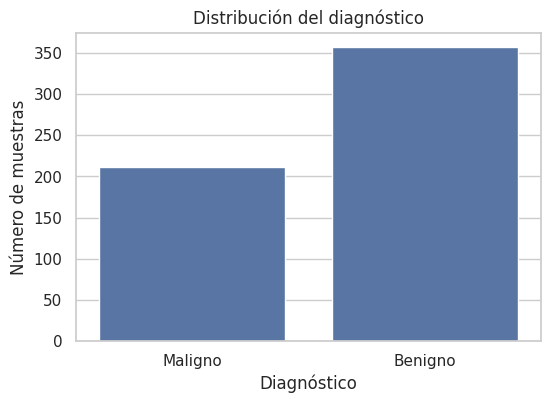

In [5]:
conteo = y.value_counts().sort_index()
resumen_clases = pd.DataFrame({'casos': conteo, 'porcentaje': (conteo / len(y) * 100).round(2)})
resumen_clases.index = ['Benigno (0)', 'Maligno (1)']
display(resumen_clases)
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
plt.figure(figsize=(6,4))
sns.countplot(x=y.map({0:'Benigno', 1:'Maligno'}))
plt.title('Distribución del diagnóstico')
plt.xlabel('Diagnóstico'); plt.ylabel('Número de muestras'); plt.show()

## 4. Distribuciones de las variables
Los histogramas permiten observar rangos, asimetrías y posibles valores extremos. Las variables tienen escalas distintas, por lo que los modelos basados en distancias o márgenes necesitarán escalamiento.

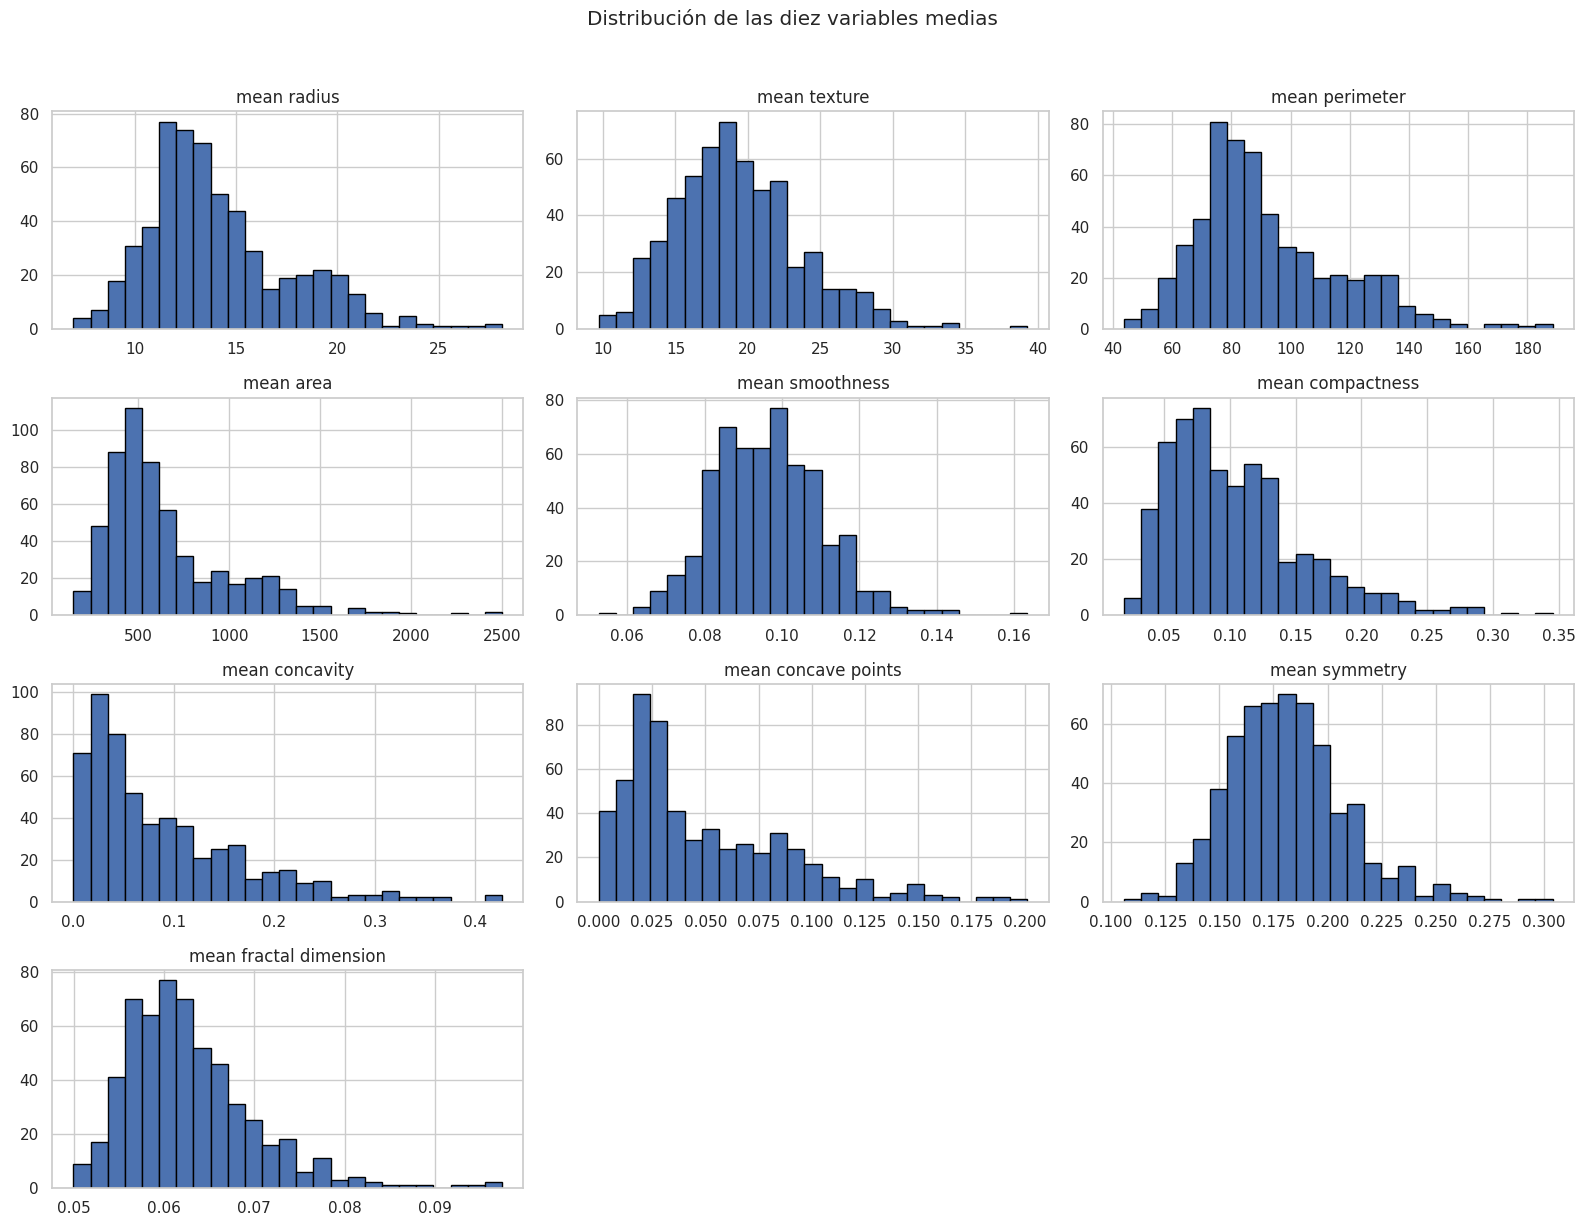

In [6]:
df[FEATURES].hist(figsize=(16,12), bins=25, edgecolor='black')
plt.suptitle('Distribución de las diez variables medias', y=1.02)
plt.tight_layout(); plt.show()

## 5. Comparación exploratoria por diagnóstico
Se comparan las distribuciones de cada variable entre muestras benignas y malignas. Estas gráficas son exploratorias y no deben interpretarse como criterios médicos aislados.

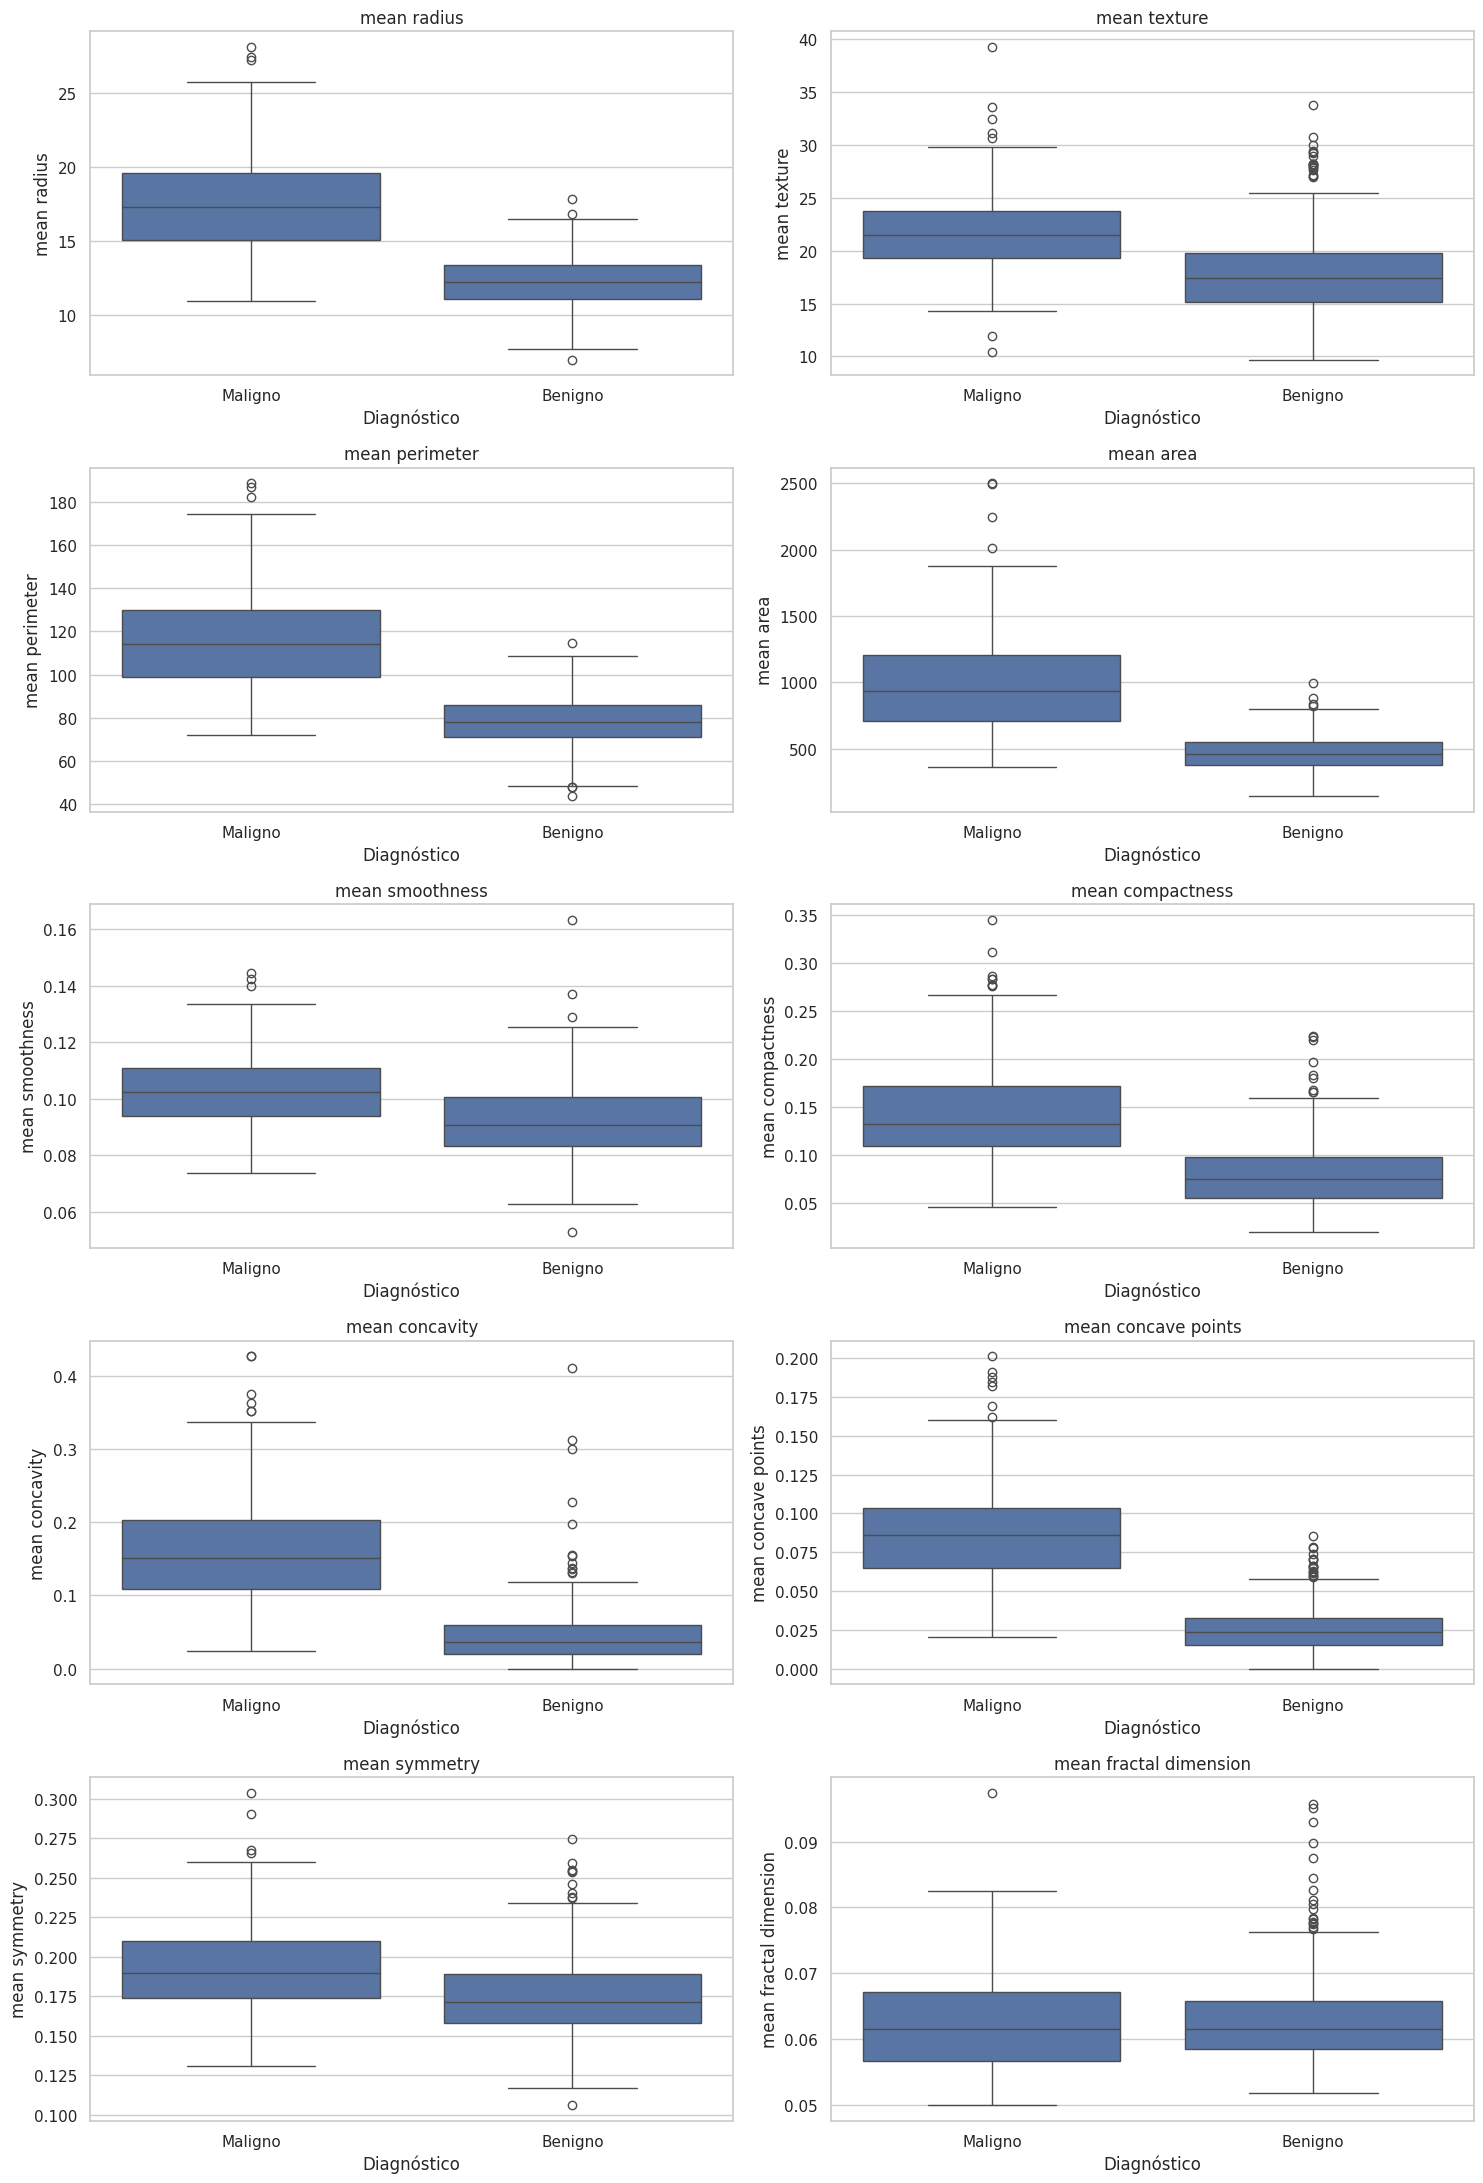

In [7]:
df_plot = df.copy()
df_plot['Diagnóstico'] = df_plot['maligno'].map({0:'Benigno', 1:'Maligno'})
fig, axes = plt.subplots(5, 2, figsize=(15, 22))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df_plot, x='Diagnóstico', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 6. Correlación entre variables
La matriz de correlación ayuda a identificar variables que presentan asociación lineal entre sí. Correlación no implica causalidad.

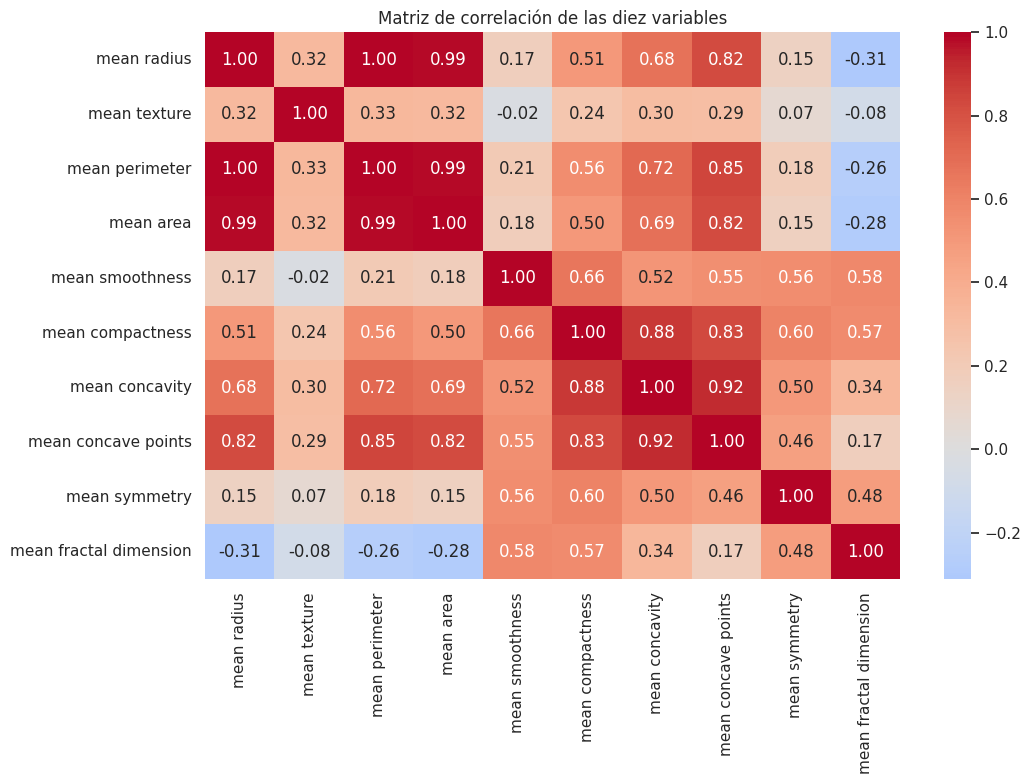

In [8]:
plt.figure(figsize=(11,8))
sns.heatmap(X.corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Matriz de correlación de las diez variables')
plt.tight_layout(); plt.show()

## 7. Detección exploratoria de valores atípicos
Se utiliza el rango intercuartílico (IQR) como una regla descriptiva. No se eliminan automáticamente estos registros: podrían contener información relevante del fenómeno.

In [9]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr
atipicos = ((X < lim_inf) | (X > lim_sup)).sum().sort_values(ascending=False)
display(atipicos.to_frame('posibles_valores_atipicos'))
print('Nota: se conservan los registros; la regla IQR solo se usa para inspección.')

,posibles_valores_atipicos
mean area,25
mean concavity,18
mean compactness,16
mean symmetry,15
mean fractal dimension,15
mean radius,14
mean perimeter,13
mean concave points,10
mean texture,7
mean smoothness,6


Nota: se conservan los registros; la regla IQR solo se usa para inspección.


## 8. Preprocesamiento y partición
Se conserva la codificación binaria del proyecto y se divide el conjunto en 80 % entrenamiento y 20 % prueba, estratificando por clase y usando `random_state=42`. El escalamiento se aplicará dentro de los *pipelines* del notebook de modelos para evitar fuga de información.

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)
print('\nProporción de malignos en entrenamiento:', round(y_train.mean(), 4))
print('Proporción de malignos en prueba:', round(y_test.mean(), 4))

Entrenamiento: (455, 10) | Prueba: (114, 10)

Proporción de malignos en entrenamiento: 0.3736
Proporción de malignos en prueba: 0.3684


## 9. Conclusiones del EDA
- El conjunto contiene observaciones etiquetadas como benignas y malignas; la clase positiva del proyecto es maligno (1).
- Las diez variables se encuentran en escalas diferentes. KNN y SVM requieren estandarización, que se incorporará dentro de sus pipelines.
- La correlación y los diagramas de caja permiten reconocer relaciones y posibles valores extremos; no se eliminan observaciones solo por ser atípicas.
- La partición estratificada 80/20 y la semilla 42 permiten mantener una evaluación comparable con el entrenamiento documentado.

**Alcance:** este análisis es académico y no constituye una herramienta de diagnóstico clínico.